# Synthetic Hyperparameter Check (multi-graph)

This notebook repeats HMRW hyperparameter sweeps on multiple independently generated synthetic hypergraphs.

- Generator: Hy-MMSBM
- Target: `avg_deg=15`
- Default size: `n_nodes=100`
- Repeat generation count: tunable (`n_graphs`)

For each hyperparameter value, the notebook evaluates embeddings on all generated graphs (and multiple seeds), then saves aggregate mean/std.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator, FormatStrFormatter

from hypergraphx.generation.hy_mmsbm_sampling import HyMMSBMSampler
from hypergraphx import Hypergraph

from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from sklearn.preprocessing import normalize

from src.utils import hmrw_embeddings


In [2]:
# Synthetic data generation settings
n_nodes = 500
n_communities = 3
avg_deg_target = 10

n_graphs = 20      # tuneable: number of independently generated hypergraphs
n_graphs = 5
n_repeats = 10      # tuneable: embedding/evaluation repeats per graph
base_seed = 42

# Hy-MMSBM sampler settings
burn_in_steps = 200
intermediate_steps = 200
exact_dyadic_sampling = True
max_hye_size = 30

# Affinity matrix (stronger within-community links)
within = 0.5
between =  (1 - within) / 2

w = np.array(
    [
        [within, between, between],
        [between, within, between],
        [between, between, within],
    ],
    dtype=float,
)


In [15]:
def evaluate_embeddings_kmeans(X, y_true, seed=42, n_clusters=3, n_kmeans_runs=10):
    Xn = normalize(X, norm="l2")

    best_inertia = None
    best_pred = None

    # Run K-means multiple times with different seeds and pick best objective.
    for t in range(n_kmeans_runs):
        km_seed = seed + t
        km = KMeans(n_clusters=n_clusters, n_init=1, random_state=km_seed)
        y_pred = km.fit_predict(Xn)

        if best_inertia is None or km.inertia_ < best_inertia:
            best_inertia = km.inertia_
            best_pred = y_pred

    print(best_pred)
    ari = adjusted_rand_score(y_true, best_pred)
    nmi = normalized_mutual_info_score(y_true, best_pred)
    return float(ari), float(nmi), float(best_inertia / Xn.shape[0])


def generate_graph_and_labels(graph_seed):
    rng = np.random.default_rng(graph_seed)

    # Hard community memberships (one-hot)
    z = rng.integers(0, n_communities, size=n_nodes)
    u = np.eye(n_communities, dtype=float)[z]

    sampler = HyMMSBMSampler(
        u=u,
        w=w,
        seed=graph_seed,
        max_hye_size=max_hye_size,
        exact_dyadic_sampling=exact_dyadic_sampling,
        burn_in_steps=burn_in_steps,
        intermediate_steps=intermediate_steps,
    )

    H = next(sampler.sample(avg_deg=avg_deg_target, allow_rescaling=True))
    nodes_sorted = sorted(H.get_nodes())
    y = z[np.asarray(nodes_sorted, dtype=int)]
    return H, y


In [5]:
results_dir = Path("results") / "synthetic" / "multi_graph_avgdeg3"
results_dir.mkdir(parents=True, exist_ok=True)

base_params = dict(
    p=1.0,
    q=1.0,
    r=1.0,
    num_walks=10,
    walk_length=40,
    window=10,
    dim=64,
    workers=8,
)

# Generate synthetic graphs ONCE and reuse across all sweeps
graph_seeds = [base_seed + 1000 + i for i in range(n_graphs)]
generated_graphs = [generate_graph_and_labels(s) for s in graph_seeds]
print("graph_seeds:", graph_seeds)

for i, (H_i, y_i) in enumerate(generated_graphs[:3]):
    avg_deg_emp = sum(len(e) for e in H_i.get_edges()) / len(H_i.get_nodes())
    print(f"graph[{i}] nodes={len(H_i.get_nodes())}, edges={len(H_i.get_edges())}, avg_deg={avg_deg_emp:.2f}, labels={len(y_i)}")


graph_seeds: [1042, 1043, 1044, 1045, 1046]
graph[0] nodes=500, edges=1221, avg_deg=9.51, labels=500
graph[1] nodes=500, edges=1227, avg_deg=9.57, labels=500
graph[2] nodes=500, edges=1235, avg_deg=10.51, labels=500


## Quick one-off run (no save)

Use this cell to sanity-check one configuration before launching resumable sweeps.

In [26]:
# One-off run across ALL pre-generated graphs (does not save CSV)
one_params = dict(base_params)
one_params.update(
    p=1,
    q=1,
    r=1.0,
    num_walks=10,
    walk_length=40,
    dim=32,
)
one_seed = base_seed

n_repeats = 1 
generated_graphs_sample = generated_graphs[:5]

ari_scores, nmi_scores, mse_scores = [], [], []
for H_one, y_one in generated_graphs_sample:
    X_one = hmrw_embeddings(H_one, seed=one_seed, **one_params)
    ari_one, nmi_one, mse_one = evaluate_embeddings_kmeans(
        X_one, y_one, seed=one_seed, n_clusters=n_communities, n_kmeans_runs=1
        )
    ari_scores.append(ari_one)
    nmi_scores.append(nmi_one)
    mse_scores.append(mse_one)

print("one_params:", one_params)
print(
    f"Across {len(generated_graphs_sample)} graphs -> "
    f"ARI={np.mean(ari_scores):.4f} ± {np.std(ari_scores):.4f}, "
    f"NMI={np.mean(nmi_scores):.4f} ± {np.std(nmi_scores):.4f}, "
    f"KMeans-MSE={np.mean(mse_scores):.4f} ± {np.std(mse_scores):.4f}"
)

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_fl

one_params: {'p': 1, 'q': 1, 'r': 1.0, 'num_walks': 10, 'walk_length': 40, 'window': 10, 'dim': 32, 'workers': 8}
Across 5 graphs -> ARI=0.0012 ± 0.0035, NMI=0.0048 ± 0.0031, KMeans-MSE=0.7683 ± 0.0025


nodes=500, edges=1221
avg_deg=9.51


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


embedding std: 0.2236
[2 1 1 1 1 2 2 1 1 0 1 1 0 2 1 1 1 1 2 0 2 0 1 1 0 2 0 2 0 2 2 1 2 2 0 0 1
 2 0 2 2 1 1 1 1 0 0 2 0 1 2 1 0 1 1 0 2 1 0 1 0 1 1 2 0 1 2 1 1 2 0 1 0 1
 2 2 1 2 1 2 0 1 2 1 1 2 2 0 1 1 1 2 2 2 1 2 1 0 1 0 2 0 1 0 1 1 1 1 0 0 2
 0 2 0 0 1 2 1 2 1 0 2 0 2 2 1 1 0 2 1 2 0 0 2 1 0 1 1 1 0 1 0 2 2 1 0 1 0
 2 2 0 2 1 0 2 1 1 0 2 1 0 1 1 0 1 0 1 1 1 1 1 0 0 2 1 1 2 0 2 1 2 2 0 2 0
 0 0 0 1 1 2 1 0 0 1 0 1 2 2 2 2 2 0 2 2 0 0 2 1 2 1 1 1 2 1 2 2 0 1 0 1 2
 2 1 1 0 2 0 2 2 2 1 1 1 0 1 1 0 1 2 2 2 0 0 2 1 1 0 1 1 2 2 1 2 0 0 1 1 1
 1 1 0 1 0 0 1 1 1 1 1 0 0 0 0 0 0 0 2 0 2 1 1 2 2 0 2 1 2 0 1 0 2 0 1 2 0
 2 1 0 2 0 1 1 0 2 1 2 0 2 2 1 2 0 1 0 2 2 2 1 2 2 2 2 0 0 2 0 1 2 1 1 2 2
 2 2 1 0 2 2 0 2 0 0 1 1 2 0 0 1 1 1 0 2 2 0 0 0 0 1 1 0 1 0 1 2 0 2 1 2 2
 2 0 2 0 0 1 1 1 1 1 2 2 1 1 1 1 0 2 2 1 1 2 2 1 2 0 2 0 1 0 1 1 1 2 0 2 1
 2 1 1 1 1 0 2 0 1 1 2 0 0 2 0 2 1 2 1 1 2 2 1 1 1 0 1 0 0 2 2 1 0 0 0 0 0
 2 0 0 0 1 1 0 2 1 2 2 0 0 0 0 0 1 0 0 2 0 0 1 2 2 0 1 0 0 2 2 1 0 2 2 2 0
 2 

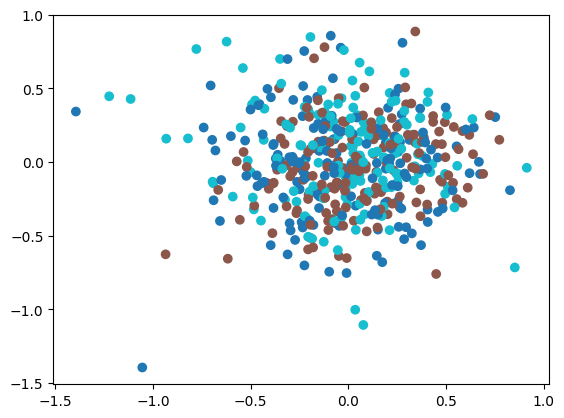

In [ ]:
from src.utils import hyper2vec_embeddings

H, y = generated_graphs[0]

print(f"nodes={len(H.get_nodes())}, edges={len(H.get_edges())}")
print(f"avg_deg={sum(len(e) for e in H.get_edges())/len(H.get_nodes()):.2f}")

X = hmrw_embeddings(H, p=1.0, q=2.0, r=1, num_walks=10, 
                     walk_length=100, dim=32, seed=42)

print(f"embedding std: {np.std(X):.4f}")  # must be non-zero

ari_one, nmi_one, mse_one = evaluate_embeddings_kmeans(
    X, y, n_clusters=3, n_kmeans_runs=1
    )
print(f"ari score: {ari_one:.4f}")  # must be non-zero

from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
Xp = PCA(n_components=2).fit_transform(X)
plt.scatter(Xp[:,0], Xp[:,1], c=y, cmap='tab10')
plt.show()  # should show 3 visible clusters

In [14]:
def run_resumable_sweep(varying_param, values, fixed_params, out_csv):
    out_csv = Path(out_csv)

    if out_csv.exists():
        df = pd.read_csv(out_csv)
    else:
        df = pd.DataFrame(columns=[
            varying_param,
            "ari_mean", "ari_std",
            "nmi_mean", "nmi_std",
            "kmeans_mse_mean", "kmeans_mse_std",
            "n_graphs", "n_repeats",
        ])

    done = set(df[varying_param].tolist()) if varying_param in df.columns else set()

    for val in values:
        if val in done:
            print(f"skip {varying_param}={val}")
            continue

        print(f"run {varying_param}={val}")
        ari_scores, nmi_scores, mse_scores = [], [], []

        n_H = 1
        for H, y in generated_graphs:
            print(f"hypergraph: n={n_H}")
            n_H += 1
            for rep in range(n_repeats):
                emb_seed = base_seed + rep
                params = dict(fixed_params)
                params[varying_param] = val

                X = hmrw_embeddings(H, seed=emb_seed, **params)
                ari, nmi, mse = evaluate_embeddings_kmeans(X, y, seed=emb_seed, n_clusters=n_communities)
                ari_scores.append(ari)
                nmi_scores.append(nmi)
                mse_scores.append(mse)

        row = {
            varying_param: val,
            "ari_mean": float(np.mean(ari_scores)),
            "ari_std": float(np.std(ari_scores)),
            "nmi_mean": float(np.mean(nmi_scores)),
            "nmi_std": float(np.std(nmi_scores)),
            "kmeans_mse_mean": float(np.mean(mse_scores)),
            "kmeans_mse_std": float(np.std(mse_scores)),
            "n_graphs": n_graphs,
            "n_repeats": n_repeats,
        }

        df = pd.concat([df, pd.DataFrame([row])], ignore_index=True)
        df.to_csv(out_csv, index=False)
        print(f"saved -> {out_csv}")

    return pd.read_csv(out_csv).sort_values(varying_param)


## Sweep q

In [15]:
q_values = [0.25, 0.5, 1.0, 2.0, 4.0]
q_csv = results_dir / "hmrw_q_sweep.csv"
results_q = run_resumable_sweep(
    varying_param="q",
    values=q_values,
    fixed_params={k: v for k, v in base_params.items() if k != "q"},
    out_csv=q_csv,
)
results_q


skip q=0.25
skip q=0.5
run q=1.0
hypergraph: n=1


KeyboardInterrupt: 

## Sweep p

In [8]:
p_values = [0.25, 0.5, 1.0, 2.0, 4.0]
p_csv = results_dir / "hmrw_p_sweep.csv"
results_p = run_resumable_sweep(
    varying_param="p",
    values=p_values,
    fixed_params={k: v for k, v in base_params.items() if k != "p"},
    out_csv=p_csv,
)
results_p


run p=0.25
hypergraph: n=1
hypergraph: n=2


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


hypergraph: n=3


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


hypergraph: n=4


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


... (146 outputs left out)

hypergraph: n=20


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


saved -> results/synthetic/multi_graph_avgdeg3/hmrw_p_sweep.csv


,p,ari_mean,ari_std,nmi_mean,nmi_std,kmeans_mse_mean,kmeans_mse_std,n_graphs,n_repeats
0,0.25,0.007310,0.006105,0.010945,0.005667,0.744057,0.008319,20,1
1,0.50,0.006798,0.008796,0.010052,0.007378,0.755142,0.007646,20,1
2,1.00,0.006798,0.006001,0.010370,0.005520,0.761567,0.007435,20,1
3,2.00,0.005123,0.005511,0.008477,0.004933,0.765783,0.007859,20,1
4,4.00,0.005605,0.005374,0.009338,0.004993,0.768401,0.006927,20,1


## Sweep r

In [9]:
r_values = [0.25, 0.5, 1.0, 2.0, 4.0]
r_csv = results_dir / "hmrw_r_sweep.csv"
results_r = run_resumable_sweep(
    varying_param="r",
    values=r_values,
    fixed_params={k: v for k, v in base_params.items() if k != "r"},
    out_csv=r_csv,
)
results_r


run r=0.25
hypergraph: n=1


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


hypergraph: n=2


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


hypergraph: n=3


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


... (150 outputs left out)

hypergraph: n=17


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


hypergraph: n=18
hypergraph: n=19
hypergraph: n=20
saved -> results/synthetic/multi_graph_avgdeg3/hmrw_r_sweep.csv


,r,ari_mean,ari_std,nmi_mean,nmi_std,kmeans_mse_mean,kmeans_mse_std,n_graphs,n_repeats
0,0.25,0.006750,0.006585,0.010497,0.006499,0.765467,0.007078,20,1
1,0.50,0.006089,0.008391,0.009411,0.007812,0.763639,0.007516,20,1
2,1.00,0.004130,0.004289,0.007764,0.004338,0.761487,0.007774,20,1
3,2.00,0.005046,0.005497,0.008634,0.005059,0.757822,0.008320,20,1
4,4.00,0.005795,0.005900,0.009168,0.005420,0.752273,0.008087,20,1


## Sweep num_walks

In [7]:
num_walks_values = [2, 5, 10, 20, 40]
num_walks_csv = results_dir / "hmrw_num_walks_sweep.csv"
results_num_walks = run_resumable_sweep(
    varying_param="num_walks",
    values=num_walks_values,
    fixed_params={k: v for k, v in base_params.items() if k != "num_walks"},
    out_csv=num_walks_csv,
)
results_num_walks


run num_walks=2
hypergraph: n=1


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


hypergraph: n=2


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


hypergraph: n=3
hypergraph: n=4


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


... (15 outputs left out)

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


hypergraph: n=3


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


KeyboardInterrupt: 

## Sweep walk_length

In [16]:
walk_length_values = [10, 20, 40, 80, 120]
walk_length_csv = results_dir / "hmrw_walk_length_sweep.csv"
results_walk_length = run_resumable_sweep(
    varying_param="walk_length",
    values=walk_length_values,
    fixed_params={k: v for k, v in base_params.items() if k != "walk_length"},
    out_csv=walk_length_csv,
)
results_walk_length


run walk_length=10
hypergraph: n=1


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


KeyboardInterrupt: 

## Sweep dim

In [17]:
dim_values = [16, 32, 64, 128, 256]
dim_csv = results_dir / "hmrw_dim_sweep.csv"
results_dim = run_resumable_sweep(
    varying_param="dim",
    values=dim_values,
    fixed_params={k: v for k, v in base_params.items() if k != "dim"},
    out_csv=dim_csv,
)
results_dim


run dim=16
hypergraph: n=1


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_fl

hypergraph: n=2


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_fl

hypergraph: n=3


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_fl

... (42 outputs left out)

hypergraph: n=5


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_fl

saved -> results/synthetic/multi_graph_avgdeg3/hmrw_dim_sweep.csv


,dim,ari_mean,ari_std,nmi_mean,nmi_std,kmeans_mse_mean,kmeans_mse_std,n_graphs,n_repeats
0,16,0.004074,0.005048,0.007346,0.004557,0.669965,0.004908,5,10
1,32,0.004047,0.007239,0.007340,0.006601,0.769061,0.003039,5,10
2,64,0.005443,0.007093,0.008621,0.006602,0.830419,0.001916,5,10
3,128,0.002552,0.004074,0.006024,0.003726,0.873576,0.001302,5,10
4,256,0.003217,0.005677,0.006597,0.005265,0.901980,0.001744,5,10


## Joint Plot (multi-graph means/std)

In [ ]:
def load_and_tag(csv_path, param_name, use_log2=False):
    df = pd.read_csv(csv_path).copy()
    df["param"] = param_name
    if use_log2:
        df["x"] = np.log2(df[param_name].to_numpy())
    else:
        df["x"] = df[param_name].to_numpy()
    return df

joint = pd.concat([
    load_and_tag(results_dir / "hmrw_p_sweep.csv", "p", use_log2=True),
    load_and_tag(results_dir / "hmrw_q_sweep.csv", "q", use_log2=True),
    load_and_tag(results_dir / "hmrw_r_sweep.csv", "r", use_log2=True),
    load_and_tag(results_dir / "hmrw_num_walks_sweep.csv", "num_walks", use_log2=False),
    load_and_tag(results_dir / "hmrw_walk_length_sweep.csv", "walk_length", use_log2=False),
    load_and_tag(results_dir / "hmrw_dim_sweep.csv", "dim", use_log2=False),
], ignore_index=True)

plot_order = ["p", "q", "r", "num_walks", "walk_length", "dim"]
label_map = {
    "p": r"$\log_2(p)$",
    "q": r"$\log_2(q)$",
    "r": r"$\log_2(r)$",
    "num_walks": "num_walks",
    "walk_length": "walk_length",
    "dim": "dim",
}

ymin = min((joint["ari_mean"] - joint["ari_std"]).min(), (joint["nmi_mean"] - joint["nmi_std"]).min())
ymax = max((joint["ari_mean"] + joint["ari_std"]).max(), (joint["nmi_mean"] + joint["nmi_std"]).max())

fig, axes = plt.subplots(2, len(plot_order), figsize=(3.6 * len(plot_order), 7), sharey=True)

for j, param in enumerate(plot_order):
    sub = joint[joint["param"] == param].sort_values("x")
    x = sub["x"].to_numpy()

    axes[0, j].plot(x, sub["ari_mean"], marker="o", color="tab:blue")
    axes[0, j].fill_between(x, sub["ari_mean"] - sub["ari_std"], sub["ari_mean"] + sub["ari_std"], alpha=0.2, color="tab:blue")
    axes[0, j].set_title(f"ARI vs {param}")
    axes[0, j].set_xlabel(label_map[param])

    axes[1, j].plot(x, sub["nmi_mean"], marker="o", color="tab:orange")
    axes[1, j].fill_between(x, sub["nmi_mean"] - sub["nmi_std"], sub["nmi_mean"] + sub["nmi_std"], alpha=0.2, color="tab:orange")
    axes[1, j].set_title(f"NMI vs {param}")
    axes[1, j].set_xlabel(label_map[param])

axes[0, 0].set_ylabel("Score")
axes[1, 0].set_ylabel("Score")

for ax in axes.ravel():
    ax.set_ylim(max(0.0, ymin - 0.01), min(1.0, ymax + 0.01))
    ax.grid(True, alpha=0.3)
    ax.yaxis.set_major_locator(MultipleLocator(0.05))
    ax.yaxis.set_major_formatter(FormatStrFormatter("%.2f"))

fig.tight_layout()
out_fig = results_dir / "hmrw_joint_sensitivity_multigraph.png"
fig.savefig(out_fig, dpi=200, bbox_inches="tight")
print(f"Saved figure: {out_fig}")
plt.show()


## Quick one-off run (no save)

In [ ]:
one_params = dict(base_params)
one_params.update(p=1.0, q=1.0, r=1.0, num_walks=10, walk_length=40, dim=128)

ari_scores, nmi_scores, mse_scores = [], [], []
for H_one, y_one in generated_graphs:
    X_one = hmrw_embeddings(H_one, seed=base_seed, **one_params)
    ari_one, nmi_one, mse_one = evaluate_embeddings_kmeans(X_one, y_one, seed=base_seed, n_clusters=n_communities)
    ari_scores.append(ari_one)
    nmi_scores.append(nmi_one)
    mse_scores.append(mse_one)

print("one_params:", one_params)
print(
    f"Across {len(generated_graphs)} graphs -> "
    f"ARI={np.mean(ari_scores):.4f} ± {np.std(ari_scores):.4f}, "
    f"NMI={np.mean(nmi_scores):.4f} ± {np.std(nmi_scores):.4f}, "
    f"KMeans-MSE={np.mean(mse_scores):.4f} ± {np.std(mse_scores):.4f}"
)
